In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Visualisation ke liye style set karna
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Processed folder se cleaned CSV files load karna
processed_dir = '../data/processed/'
eda_dfs = {}

if os.path.exists(processed_dir):
    files = [f for f in os.listdir(processed_dir) if f.endswith('.csv')]
    for file in files:
        table_name = file.replace('cleaned_', '').replace('.csv', '')
        eda_dfs[table_name] = pd.read_csv(os.path.join(processed_dir, file))
        print(f"Loaded {table_name} for EDA, Shape: {eda_dfs[table_name].shape}")
else:
    print("Processed directory not found. Please run data cleaning first.")

Loaded churn_features for EDA, Shape: (12180, 15)
Loaded cities for EDA, Shape: (25, 5)
Loaded customers for EDA, Shape: (12019, 13)
Loaded customer_feedback for EDA, Shape: (14200, 7)
Loaded delivery_partners for EDA, Shape: (2000, 10)
Loaded menu for EDA, Shape: (8997, 8)
Loaded orders for EDA, Shape: (20639, 15)
Loaded order_items for EDA, Shape: (42378, 6)
Loaded payments for EDA, Shape: (20493, 6)
Loaded promotions for EDA, Shape: (300, 6)
Loaded restaurants for EDA, Shape: (1200, 13)
Loaded traffic for EDA, Shape: (18335, 6)
Loaded weather for EDA, Shape: (18264, 7)
Loaded delivery_features for EDA, Shape: (20705, 36)


<class 'pandas.DataFrame'>
RangeIndex: 20639 entries, 0 to 20638
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   orderid              20639 non-null  int64  
 1   customerid           20639 non-null  int64  
 2   restaurantid         20639 non-null  int64  
 3   deliverypartnerid    20639 non-null  int64  
 4   orderdate            20639 non-null  str    
 5   ordertime            20639 non-null  str    
 6   deliverytimeminutes  20639 non-null  int64  
 7   foodcost             20639 non-null  int64  
 8   deliveryfee          20639 non-null  int64  
 9   discount             20639 non-null  float64
 10  couponcode           20639 non-null  str    
 11  gst                  20639 non-null  float64
 12  finalamount          20639 non-null  float64
 13  orderstatus          20639 non-null  str    
 14  paymentmethod        20639 non-null  str    
dtypes: float64(3), int64(7), str(5)
memory usage: 3

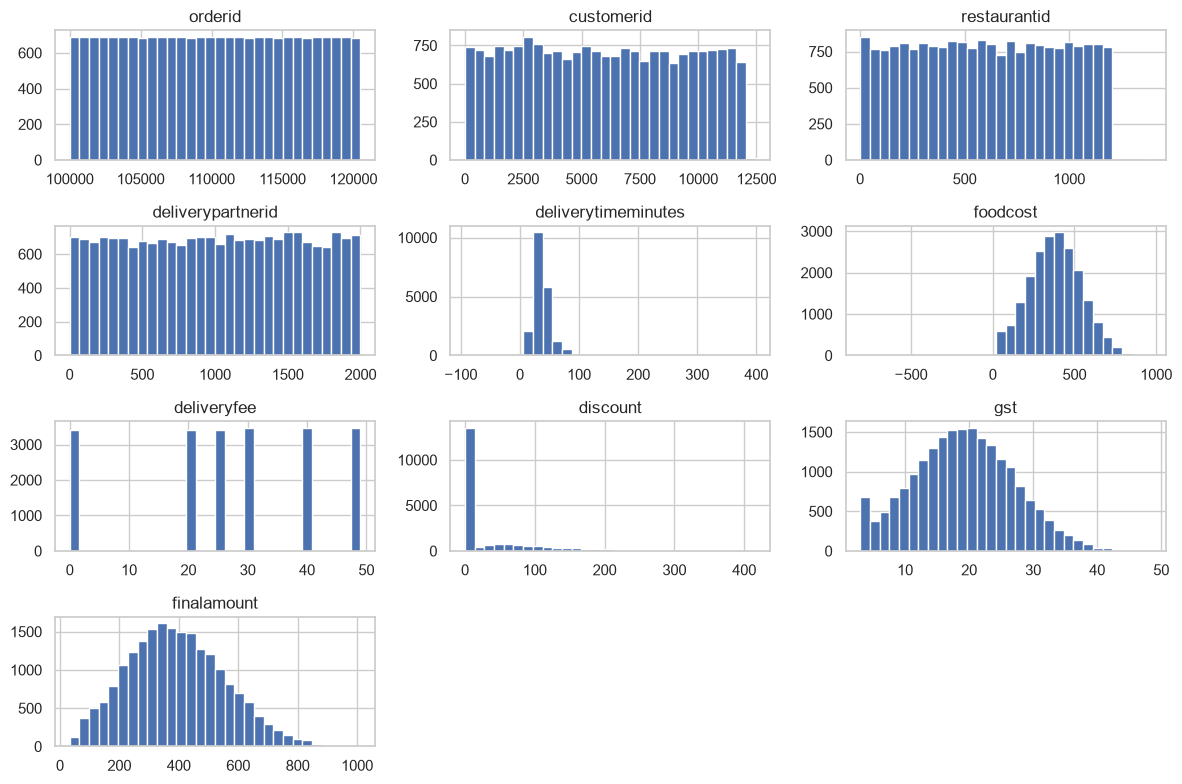

In [3]:
# उदाहरण के लिए अगर 'orders' या मुख्य टेबल मौजूद है, तो उसके न्यूमेरिकल कॉलम्स का डिस्ट्रीब्यूशन देखना
# (अपने डेटाबेस की मुख्य टेबल के नाम के अनुसार 'orders' को बदल सकते हैं)
target_table = 'orders' # अपनी मुख्य टेबल का नाम यहाँ जाँच लें

if target_table in eda_dfs:
    df_sample = eda_dfs[target_table]
    print(df_sample.info())
    
    # न्यूमेरिकल कॉलम्स के लिए हिस्टोग्राम प्लॉट करना
    df_sample.hist(bins=30, figsize=(12, 8))
    plt.tight_layout()
    plt.show()
else:
    print(f"Table '{target_table}' not found in loaded data.")

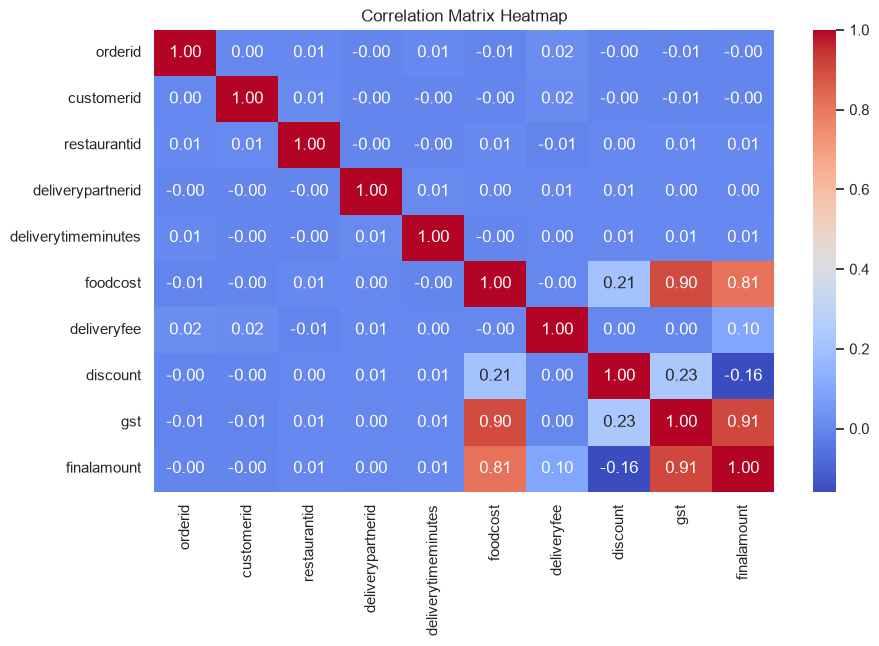

In [4]:
# न्यूमेरिकल कॉलम्स के बीच कोरिलेशन मैट्रिक्स और हीटमैप
if target_table in eda_dfs:
    plt.figure(figsize=(10, 6))
    numeric_df = eda_dfs[target_table].select_dtypes(include=[np.number])
    
    if not numeric_df.empty:
        sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
        plt.title("Correlation Matrix Heatmap")
        plt.show()
    else:
        print("No numeric columns available for correlation.")